# Transfer attack scatter — figures only

Thin driver for `analytics.attacks.run_transfer_scatter_figures`. Edit the **config** cell only; plotting logic lives in the library.

Produces PNGs under `outputs/transfer_scatter_figures/` (no summary CSV, interpretation, or outlier markdown).

**Family attack lens** (`attack_lens_classical` / `hybrid` / `quantum`): all models plotted; x uses pairs attacking that family’s targets, y uses pairs from that family’s sources.

In [6]:
import sys
from pathlib import Path

_project_root = Path.cwd().resolve()
while _project_root != _project_root.parent and not (_project_root / "src" / "analytics").is_dir():
    _project_root = _project_root.parent
if not (_project_root / "src" / "analytics").is_dir():
    raise FileNotFoundError(
        "Could not find the project root (expected src/analytics/). "
        "Set the notebook working directory to the QB-PIER repo root."
    )
_src = _project_root / "src"
if str(_src) not in sys.path:
    sys.path.insert(0, str(_src))

from analytics.notebook_setup import notebook_paths

project_root, TRAINING_ROOT, ATTACK_EXPERIMENT_DIR, OUT, _src = notebook_paths(
    "transfer_scatter_figures", start=_project_root
)

## Config — edit here

In [7]:
from analytics.attacks import ATTACK_TABLE_METRICS, available_transfer_metrics
from analytics.attacks.transfer_scatter import TransferScatterPlotOptions

# --- Metric (same names as attack_matrix.ipynb: ASR, robust_accuracy, ...) ---
# robust_accuracy ~0.05-0.6: default 40-100% clip auto-expands if data would be hidden
METRIC = "robust_accuracy"

# --- Pair metrics (optional cache on disk) ---
PAIR_METRICS_PATH = OUT / "pair_metrics.csv"  # set to None to skip saving

# --- Transfer filters to plot ---
FILTER_MODES = [
    "inter_model",
    "inter_architecture",
    "inter_family",
    "attack_lens_classical",
    "attack_lens_hybrid",
    "attack_lens_quantum",
]

# --- Which figures ---
GENERATE_ARCHITECTURE = True
GENERATE_VARIANT = True

# Variant point size: analytics/attacks/dump_params_size.json (canonical path → param count)

# --- Figure styling (see TransferScatterPlotOptions) ---
PLOT_OPTIONS = TransferScatterPlotOptions(
    metric=METRIC,
    xlim=(0.45, 0.9),
    ylim=(0.5, 0.9),
    clip_axes=True,
    show_quadrant_annotations=True,
    show_point_labels=True,
)

In [8]:
from analytics.tables.extract_attack import build_pair_metrics

pair_df, _per_seed = build_pair_metrics(
    attack_dir=ATTACK_EXPERIMENT_DIR,
    output_path=PAIR_METRICS_PATH,
)
bb = int((pair_df["WB/BB Flag"] == "BB").sum())
wb = int((pair_df["WB/BB Flag"] == "WB").sum())
print(f"Pair metrics: {len(pair_df)} rows (WB={wb}, BB={bb})")
print("Supported metrics:", available_transfer_metrics(pair_df))
print("All attack-table metrics:", list(ATTACK_TABLE_METRICS))

Blacklisted rows removed: 2814
Pair metrics: 1089 rows (WB=33, BB=1056)
Supported metrics: ['ASR', 'robust_accuracy', 'flip_rate', 'mean_confidence_drop_all', 'mean_margin_drop_all', 'mean_confidence_drop_cc', 'mean_margin_drop_cc', 'transfer_gap']
All attack-table metrics: ['robust_accuracy', 'flip_rate', 'ASR', 'mean_confidence_drop_all', 'mean_margin_drop_all', 'mean_confidence_drop_cc', 'mean_margin_drop_cc', 'transfer_gap']


In [9]:
from analytics.attacks.transfer_scatter import run_transfer_scatter_figures

figure_paths = run_transfer_scatter_figures(
    pair_df,
    OUT,
    project_root=project_root,
    plot_options=PLOT_OPTIONS,
    filter_modes=FILTER_MODES,
    generate_architecture=GENERATE_ARCHITECTURE,
    generate_variant=GENERATE_VARIANT,
)
for name, path in sorted(figure_paths.items()):
    print(f"{name}: {path}")

Axis clip x=(0.45, 0.9) y=(0.5, 0.9) hides robust_accuracy data (x=[0.226, 0.475], y=[0.230, 0.322]); using data range.
Axis clip x=(0.45, 0.9) y=(0.5, 0.9) hides robust_accuracy data (x=[0.202, 0.475], y=[0.140, 0.429]); using data range.
Axis clip x=(0.45, 0.9) y=(0.5, 0.9) hides robust_accuracy data (x=[0.226, 0.475], y=[0.247, 0.324]); using data range.
Axis clip x=(0.45, 0.9) y=(0.5, 0.9) hides robust_accuracy data (x=[0.203, 0.475], y=[0.149, 0.448]); using data range.
Axis clip x=(0.45, 0.9) y=(0.5, 0.9) hides robust_accuracy data (x=[0.189, 0.434], y=[0.244, 0.346]); using data range.
Axis clip x=(0.45, 0.9) y=(0.5, 0.9) hides robust_accuracy data (x=[0.189, 0.434], y=[0.154, 0.480]); using data range.


architecture_inter_architecture__robust_accuracy: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter_figures\architecture_inter_architecture__robust_accuracy.png
architecture_inter_family__robust_accuracy: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter_figures\architecture_inter_family__robust_accuracy.png
architecture_inter_model__robust_accuracy: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter_figures\architecture_inter_model__robust_accuracy.png
variant_inter_architecture__robust_accuracy: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter_figures\variant_inter_architecture__robust_accuracy.png
variant_inter_family__robust_accuracy: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter_figures\variant_inter_family__robust_accuracy.png
variant_inter_model__robust_accuracy: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter_figures\variant_inter_model__robust_accuracy.png


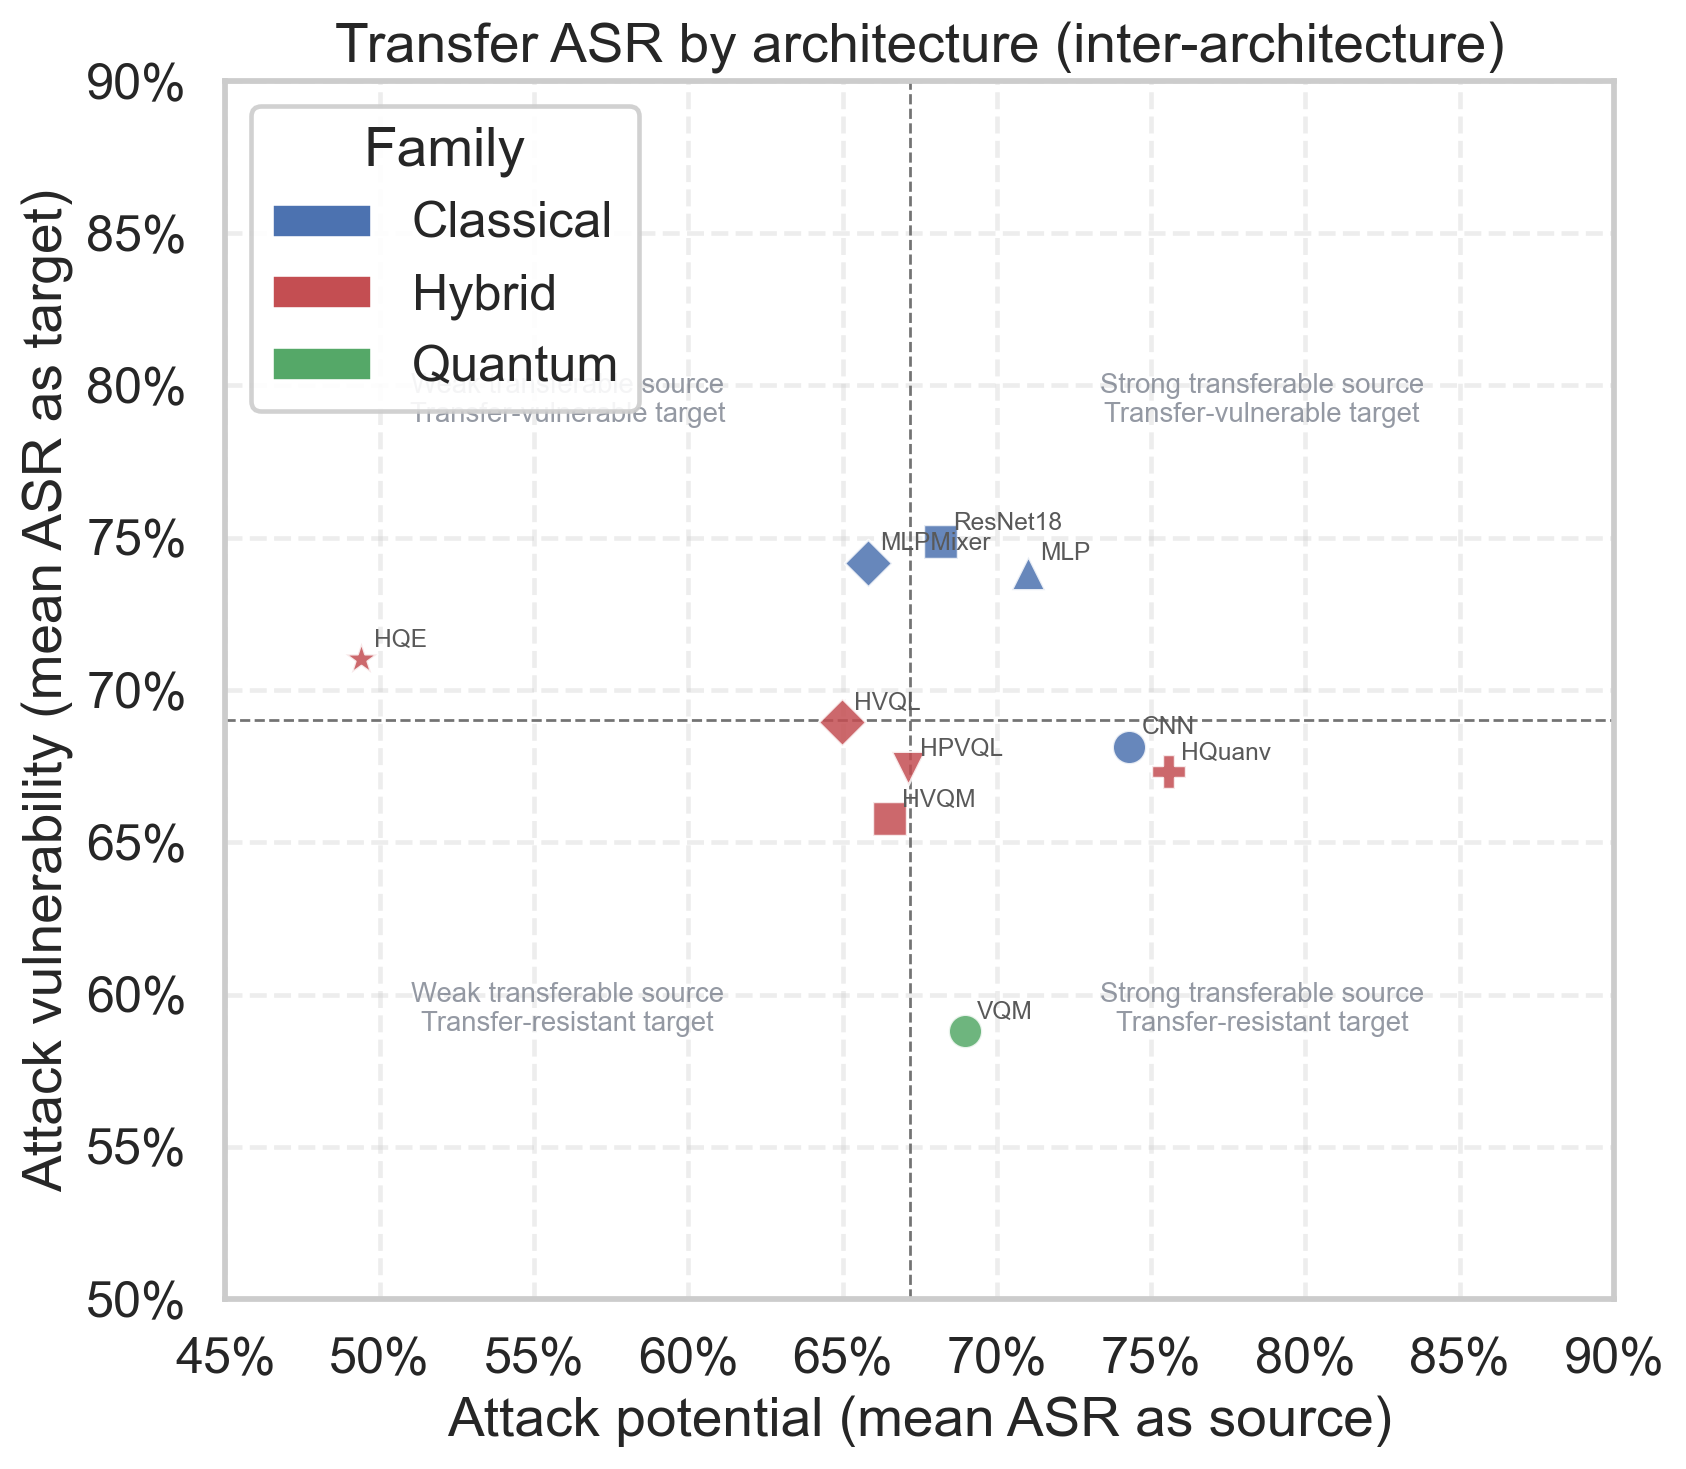

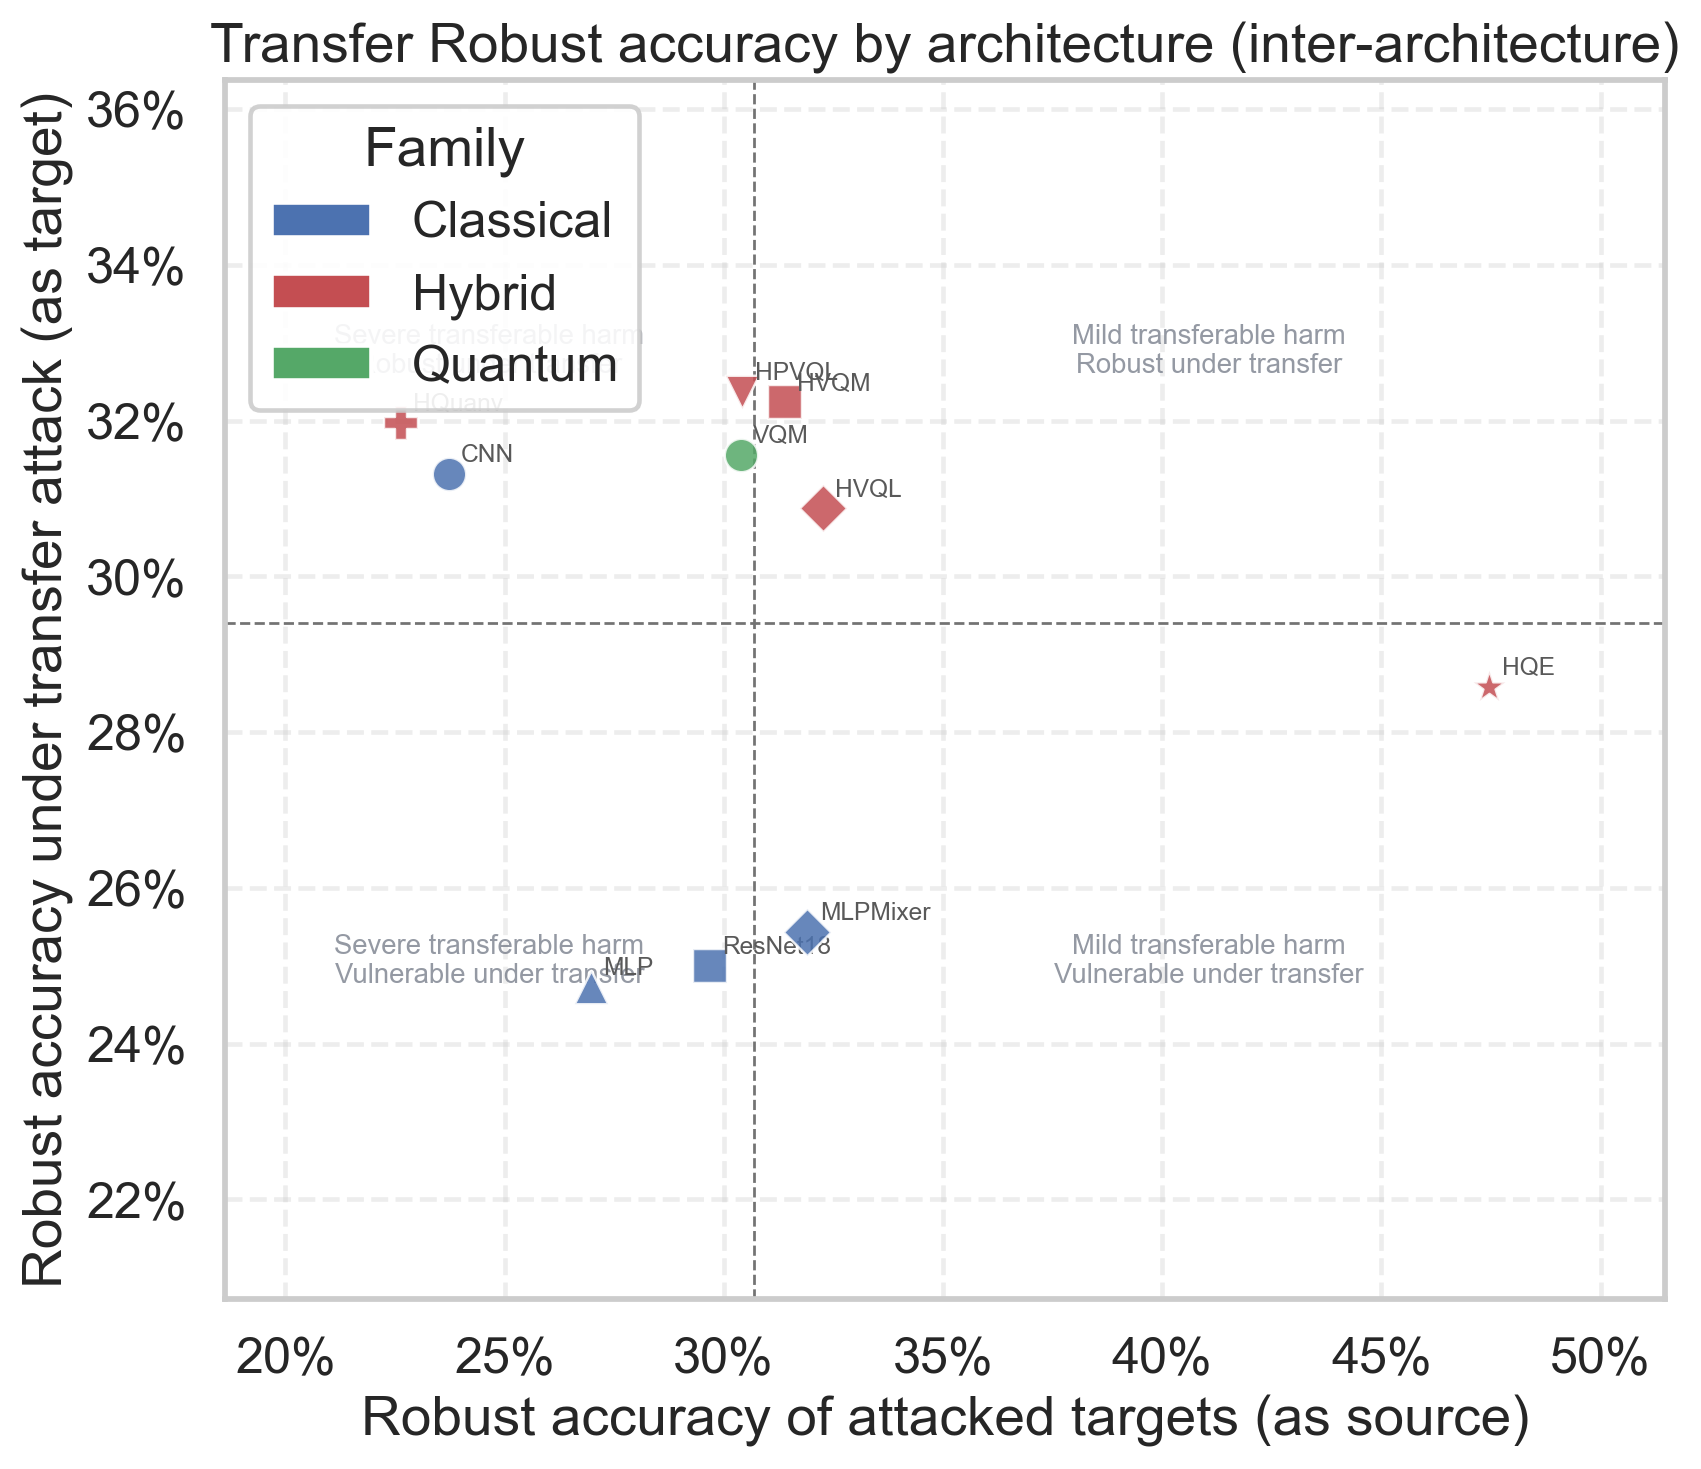

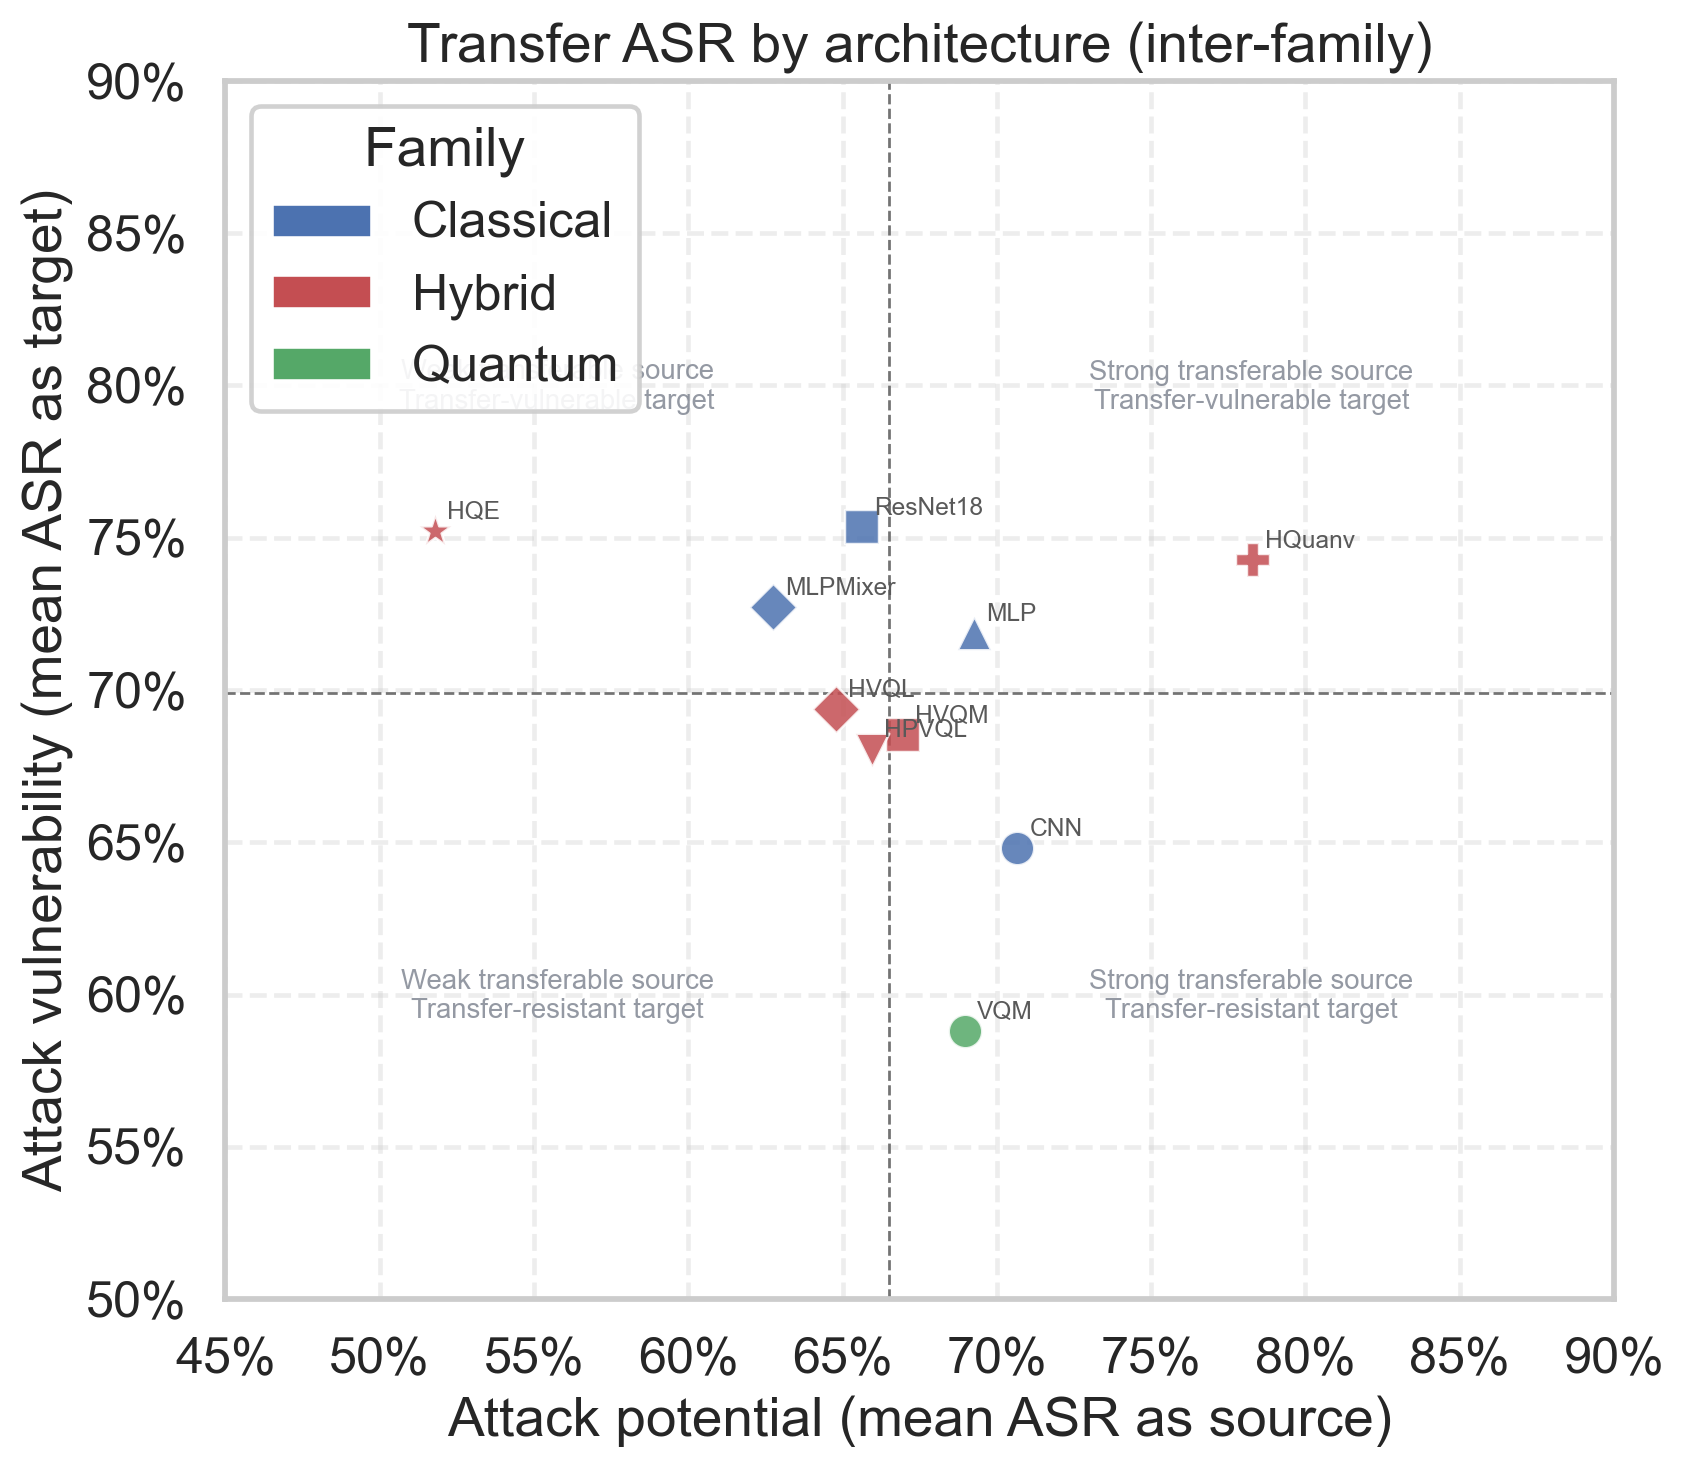

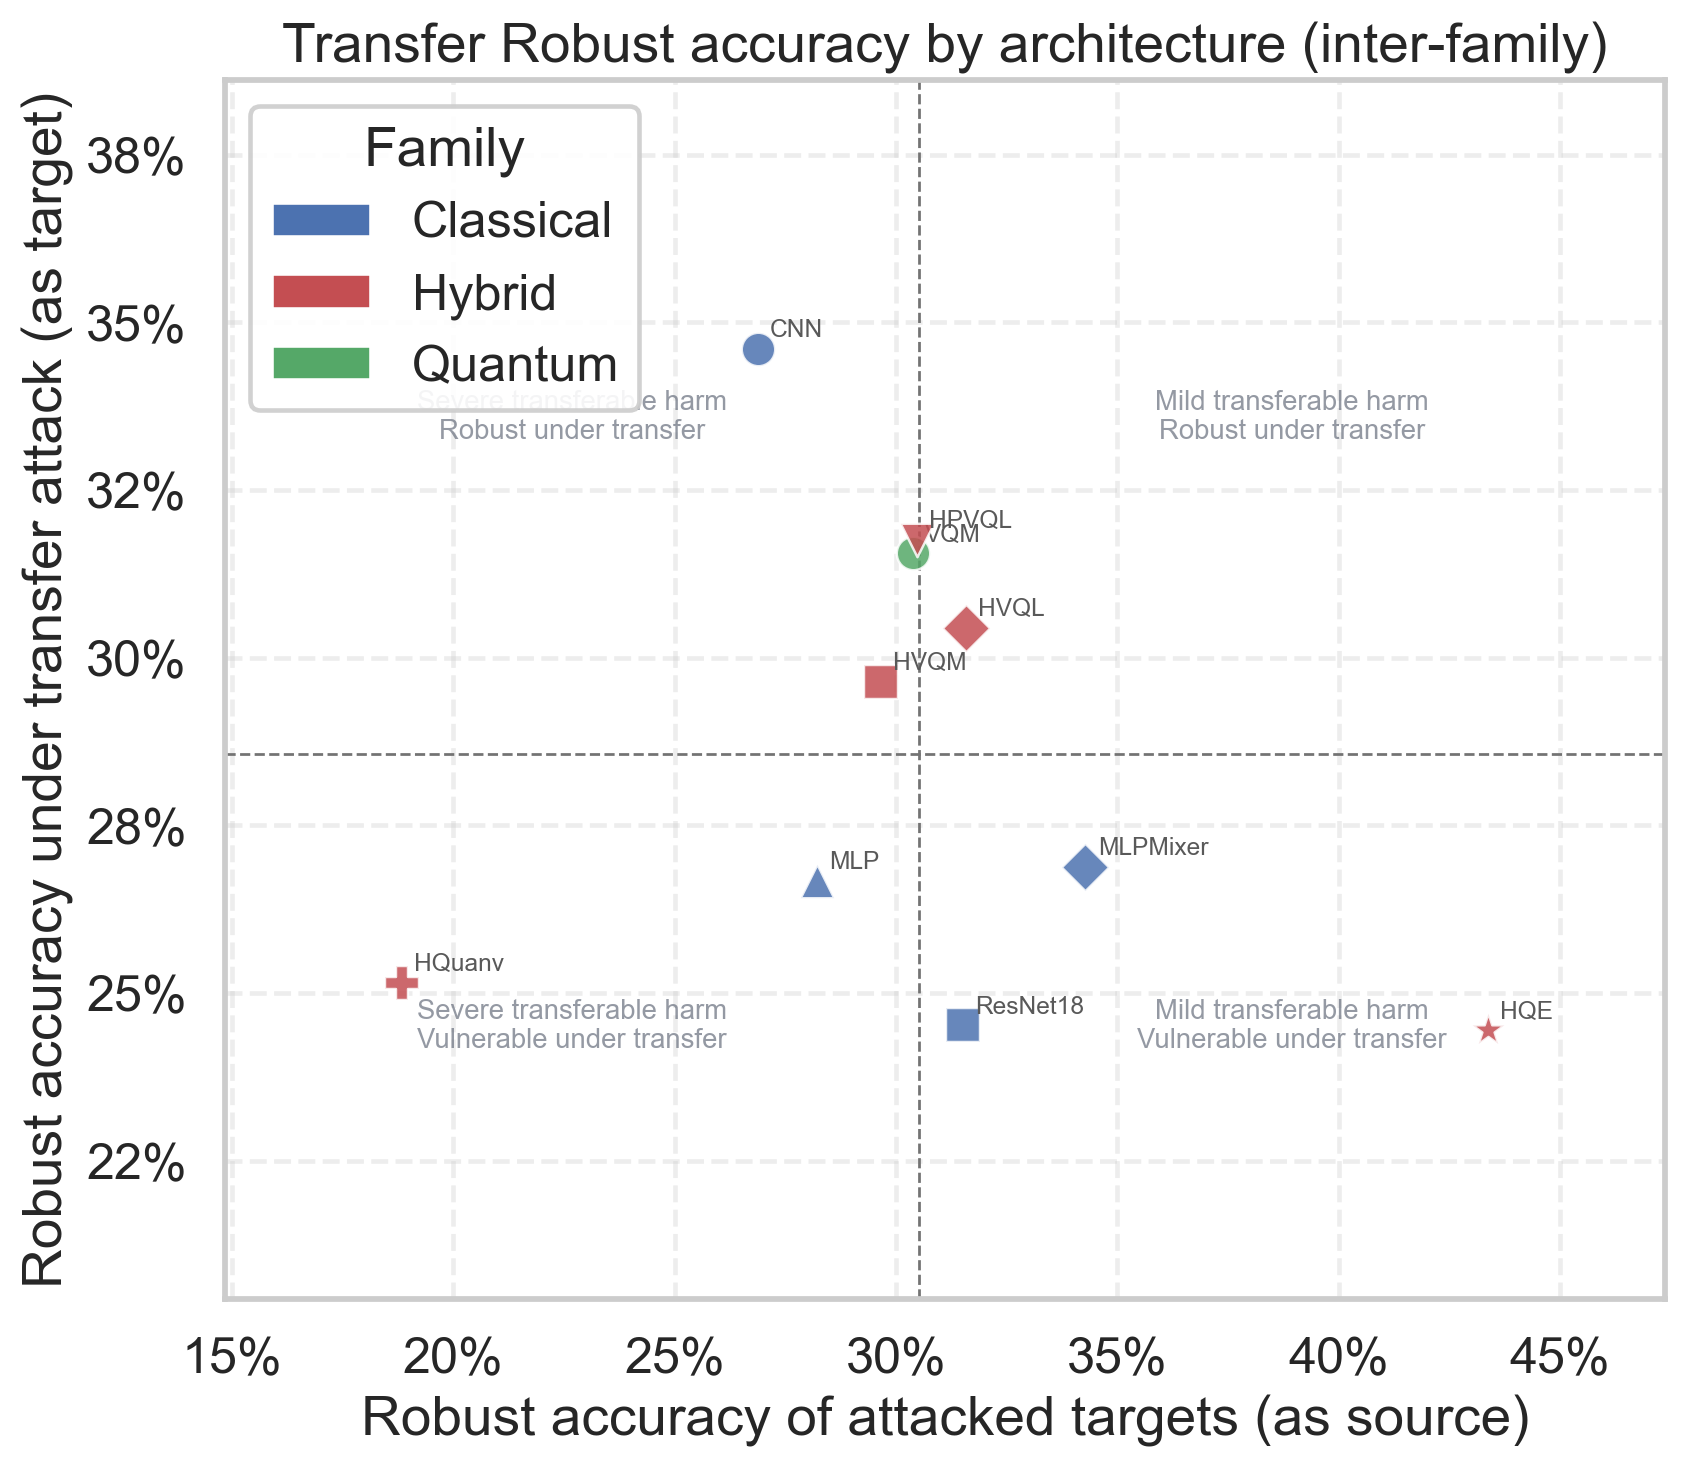

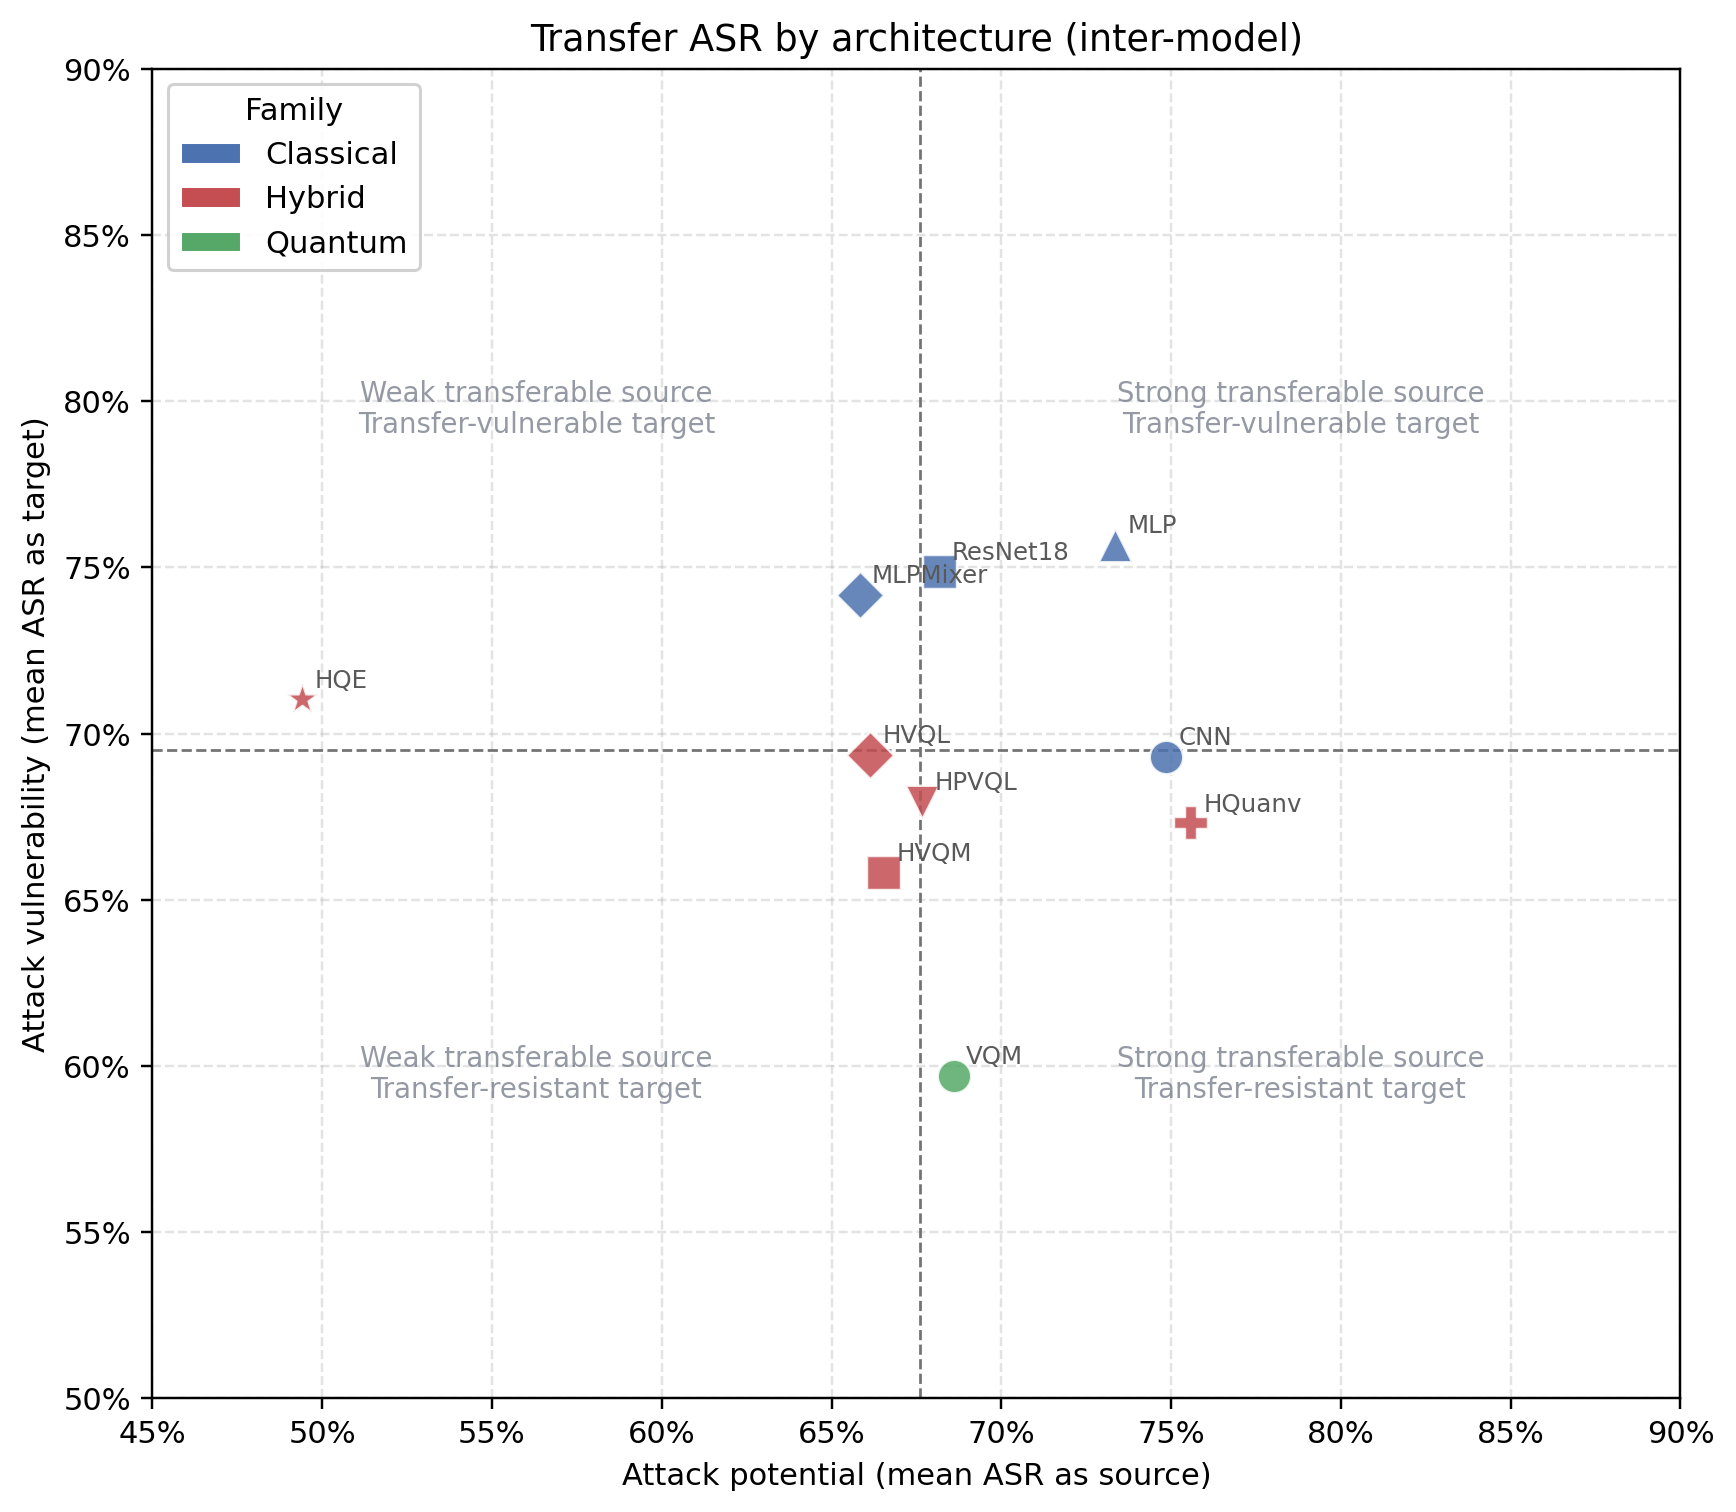

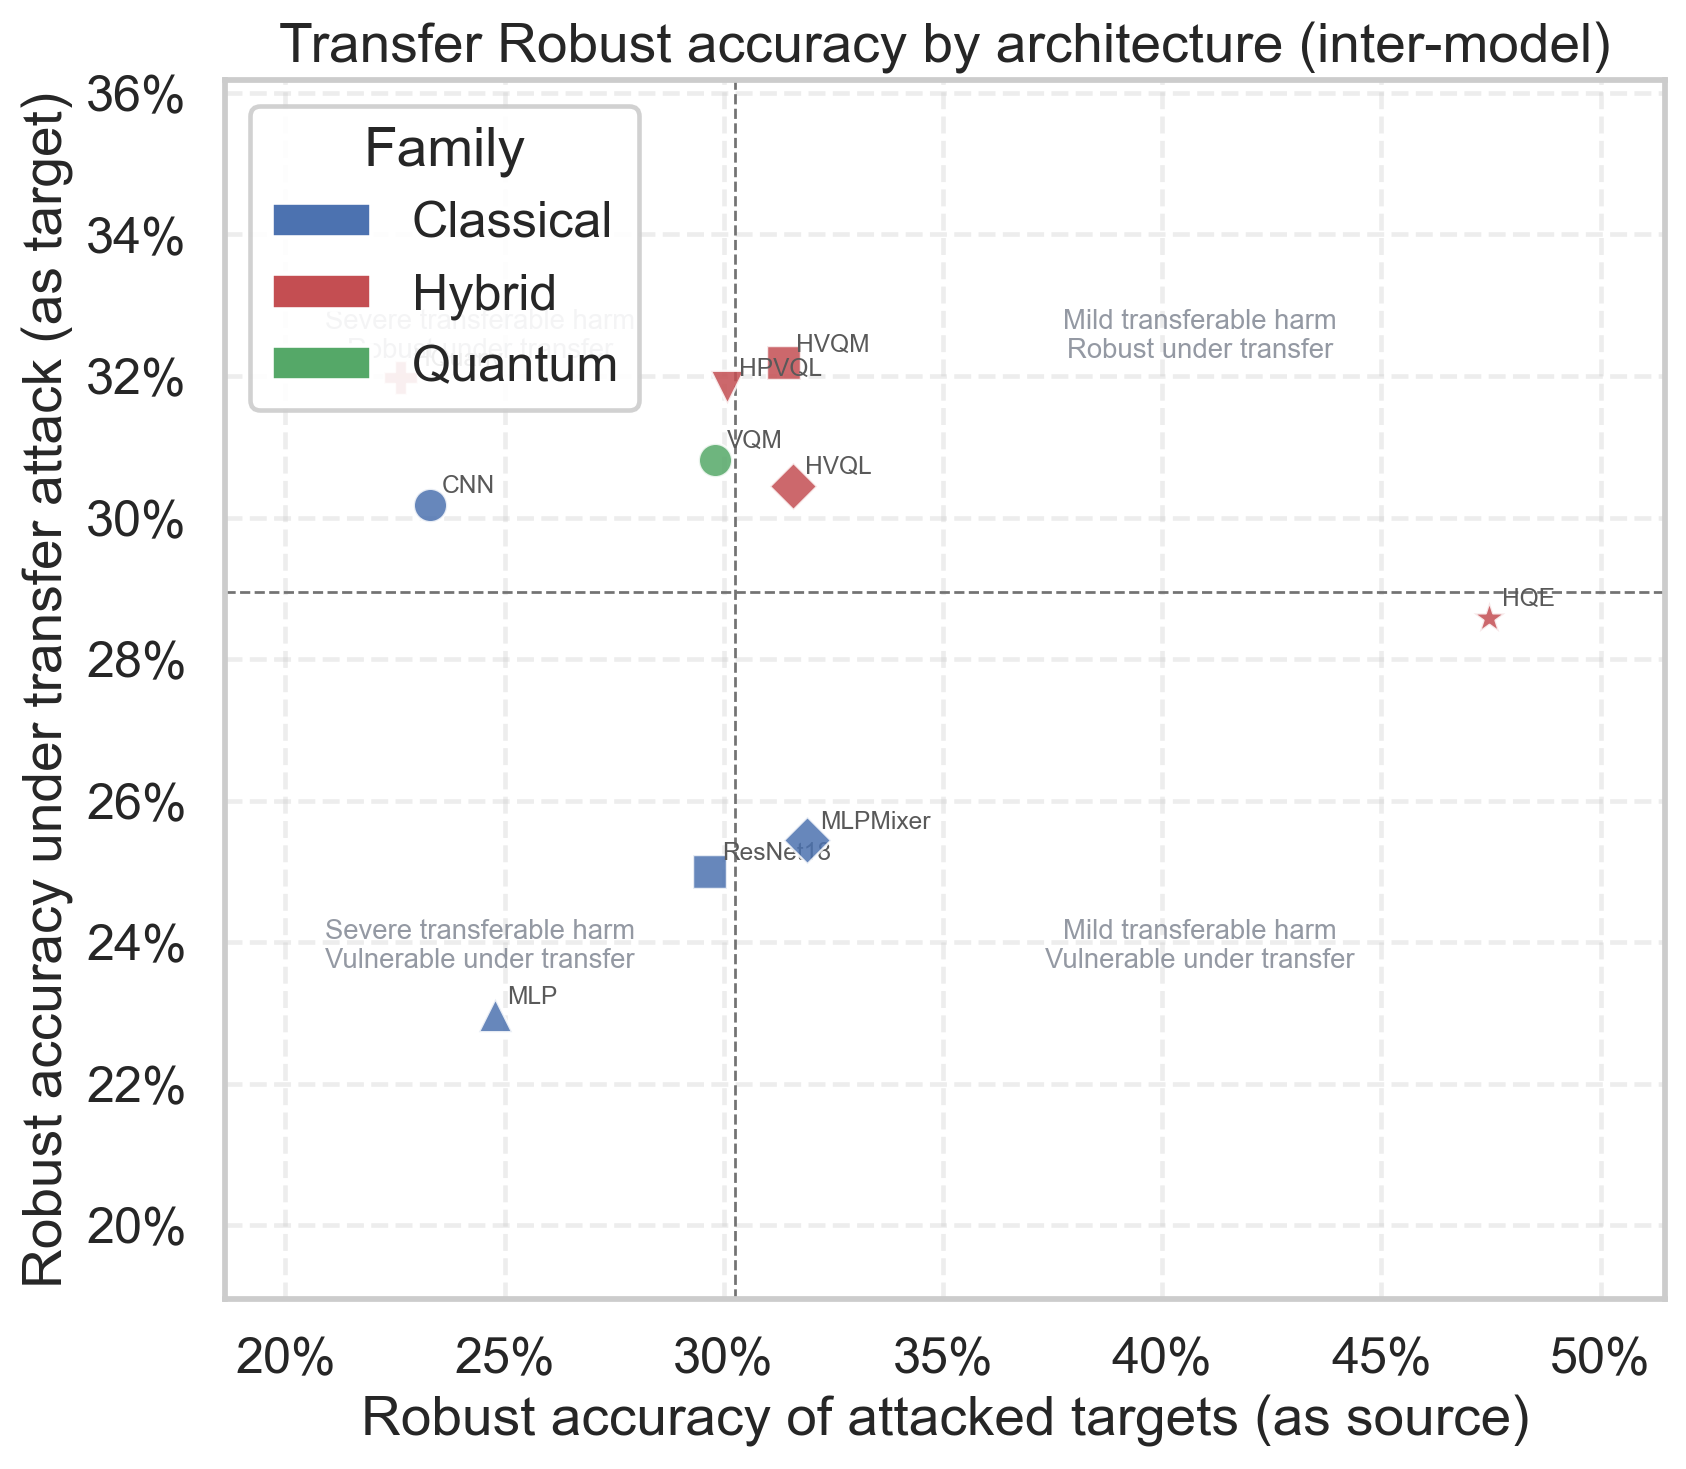

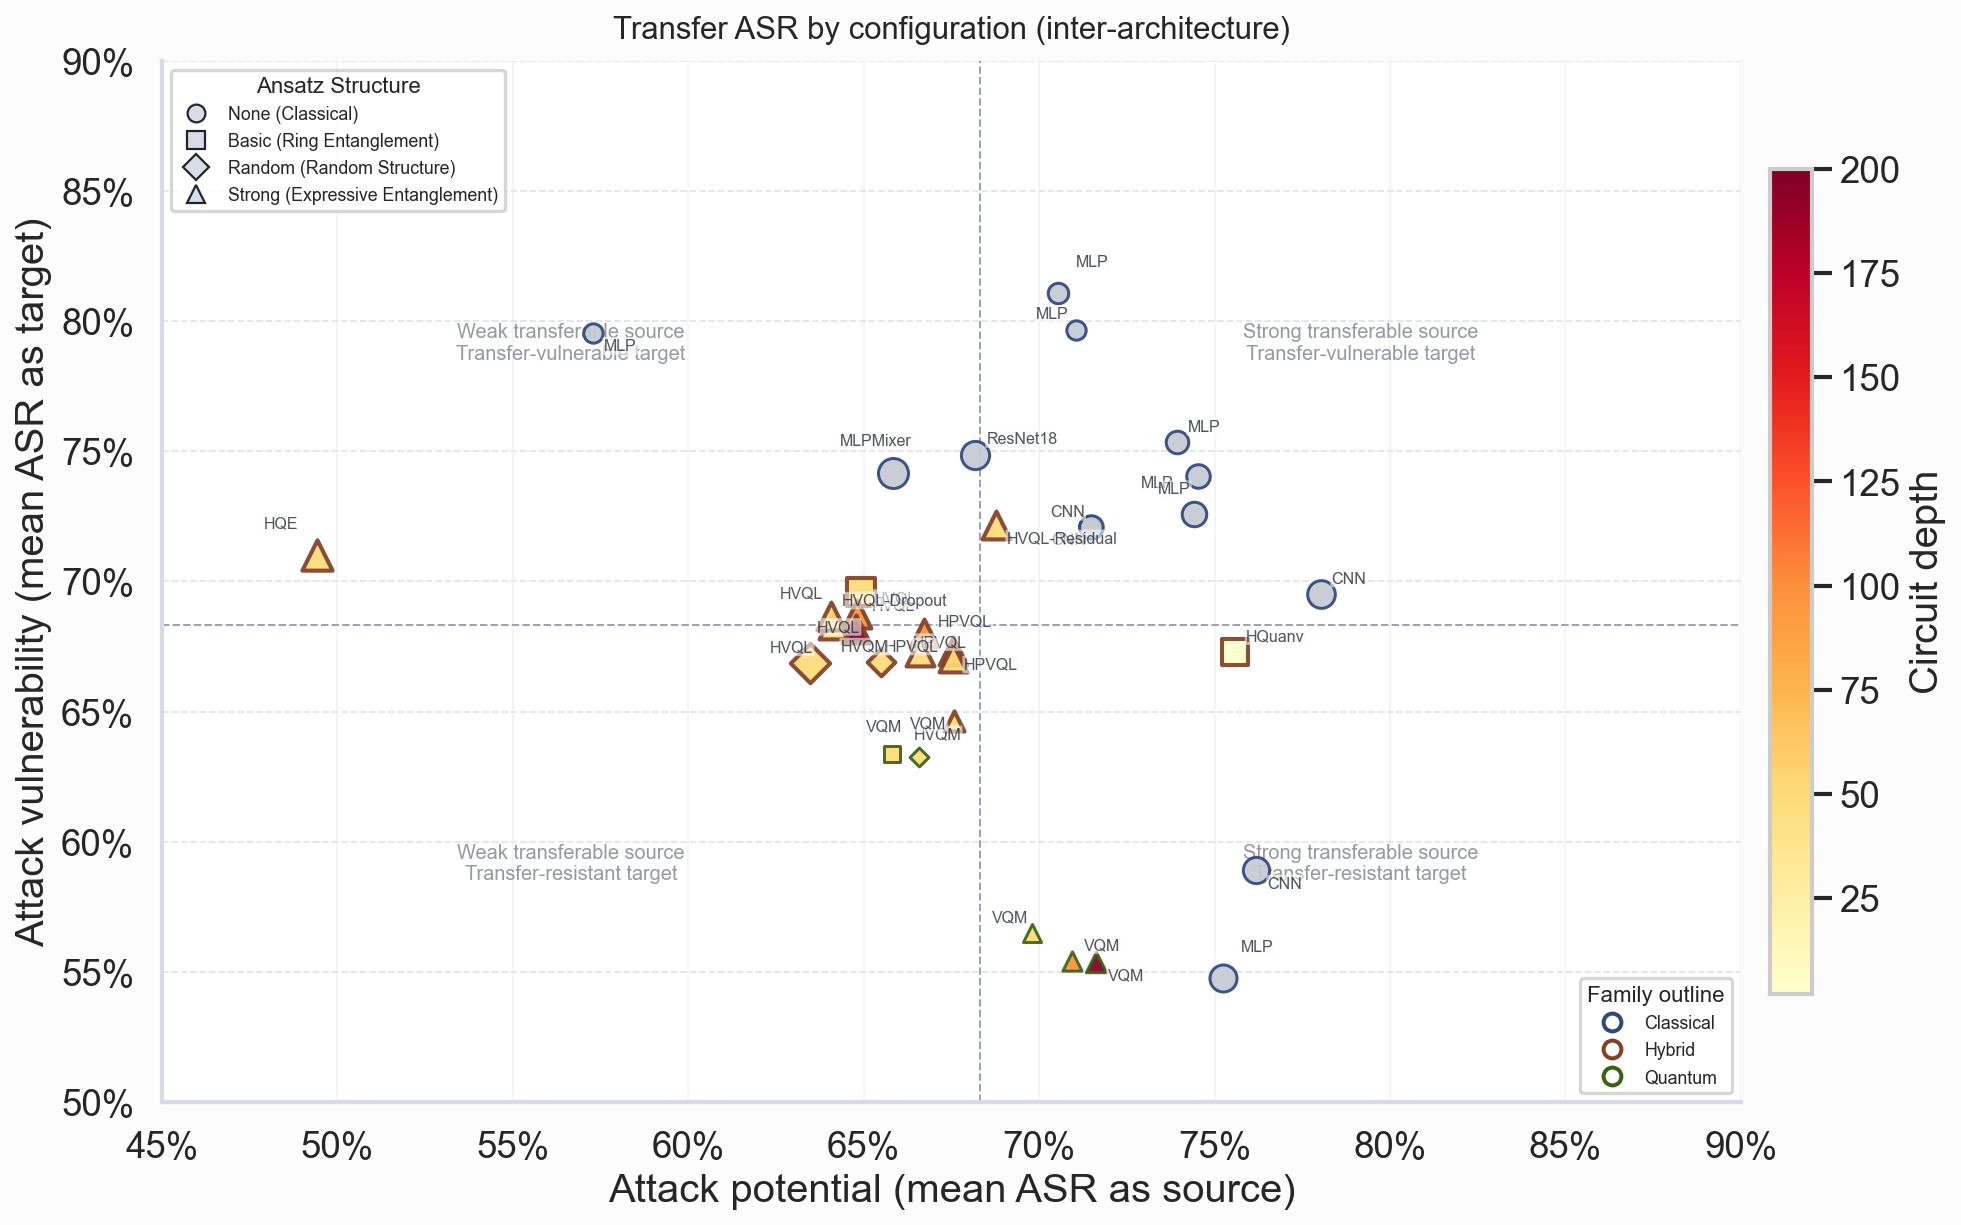

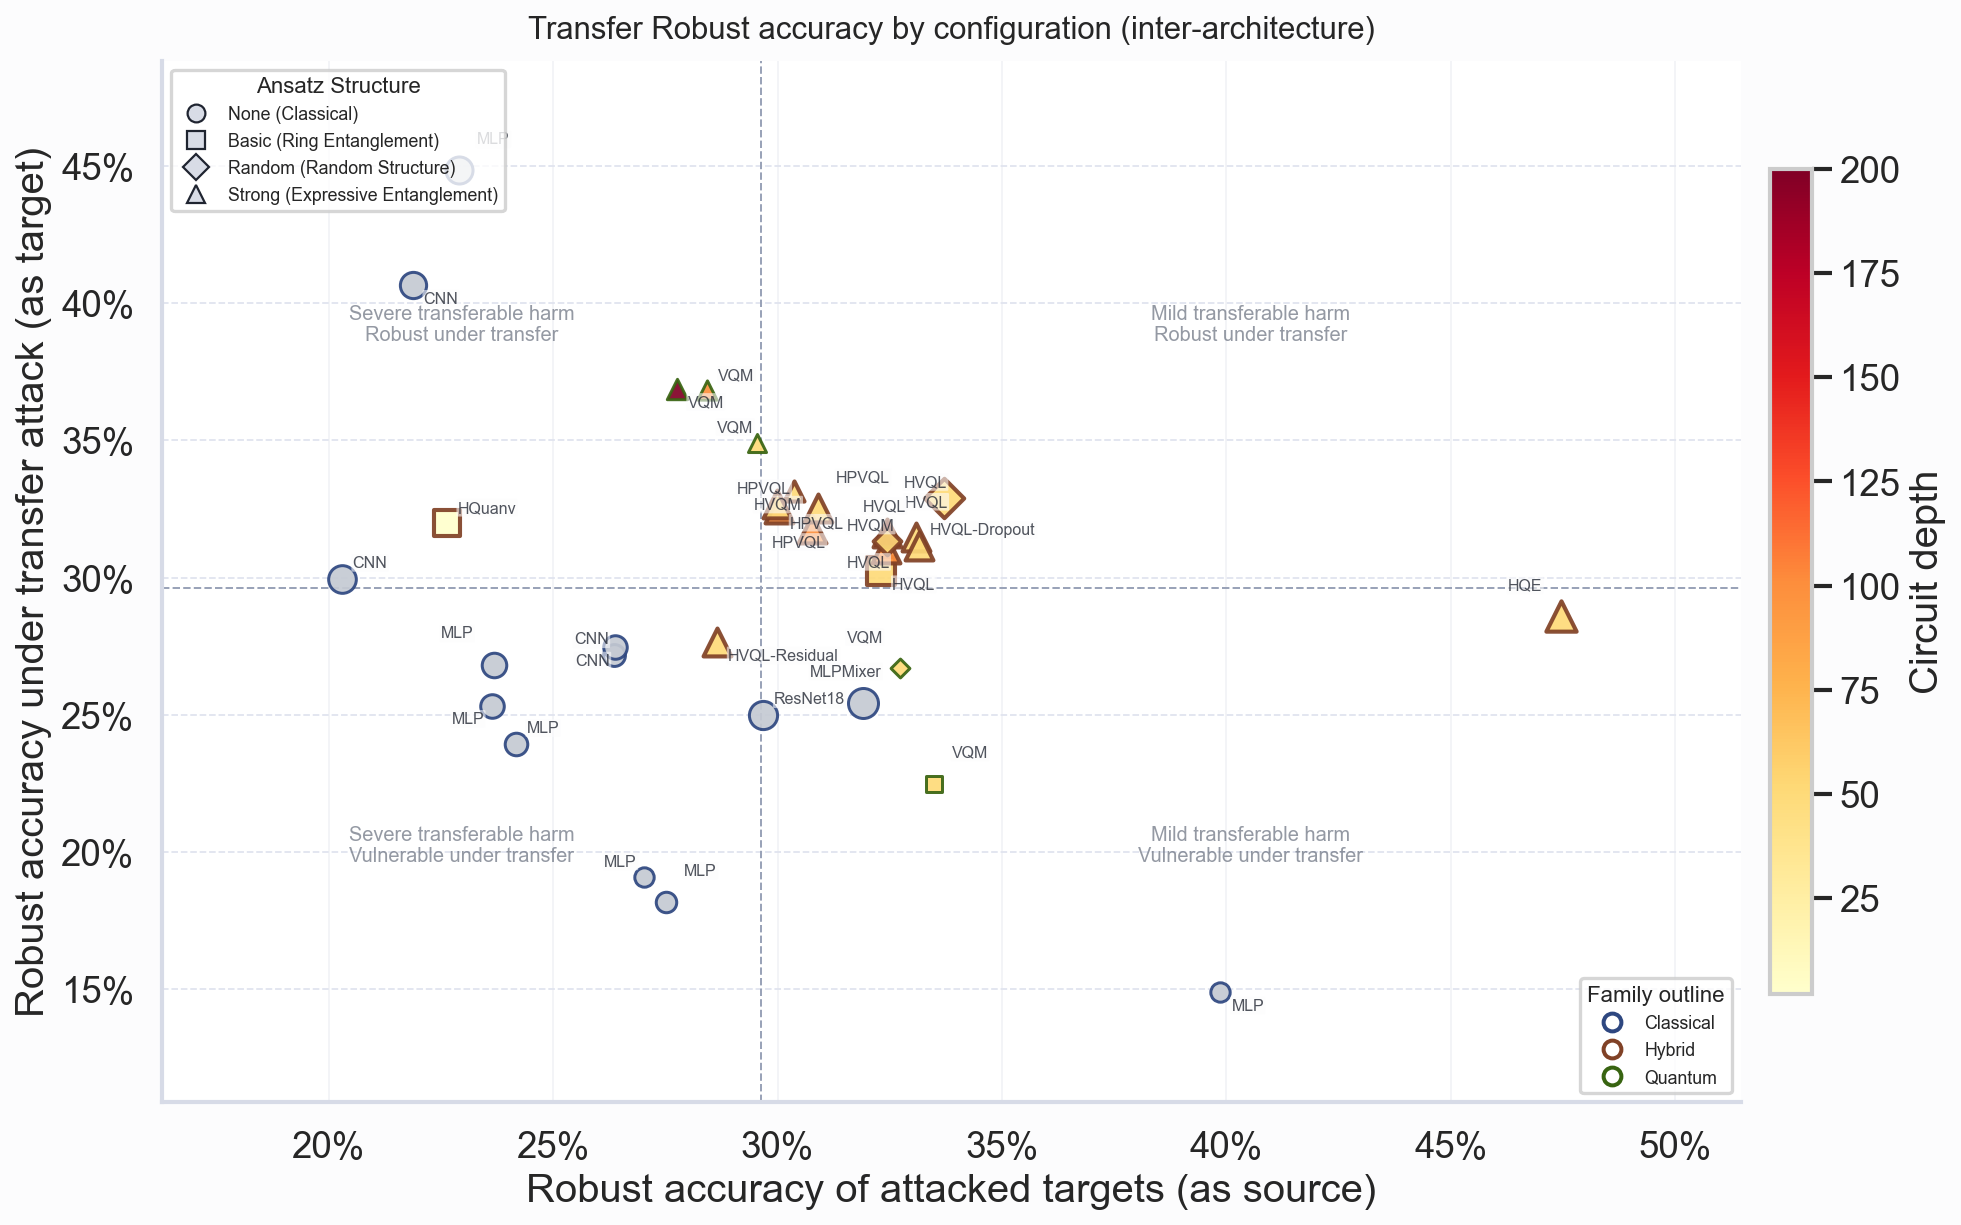

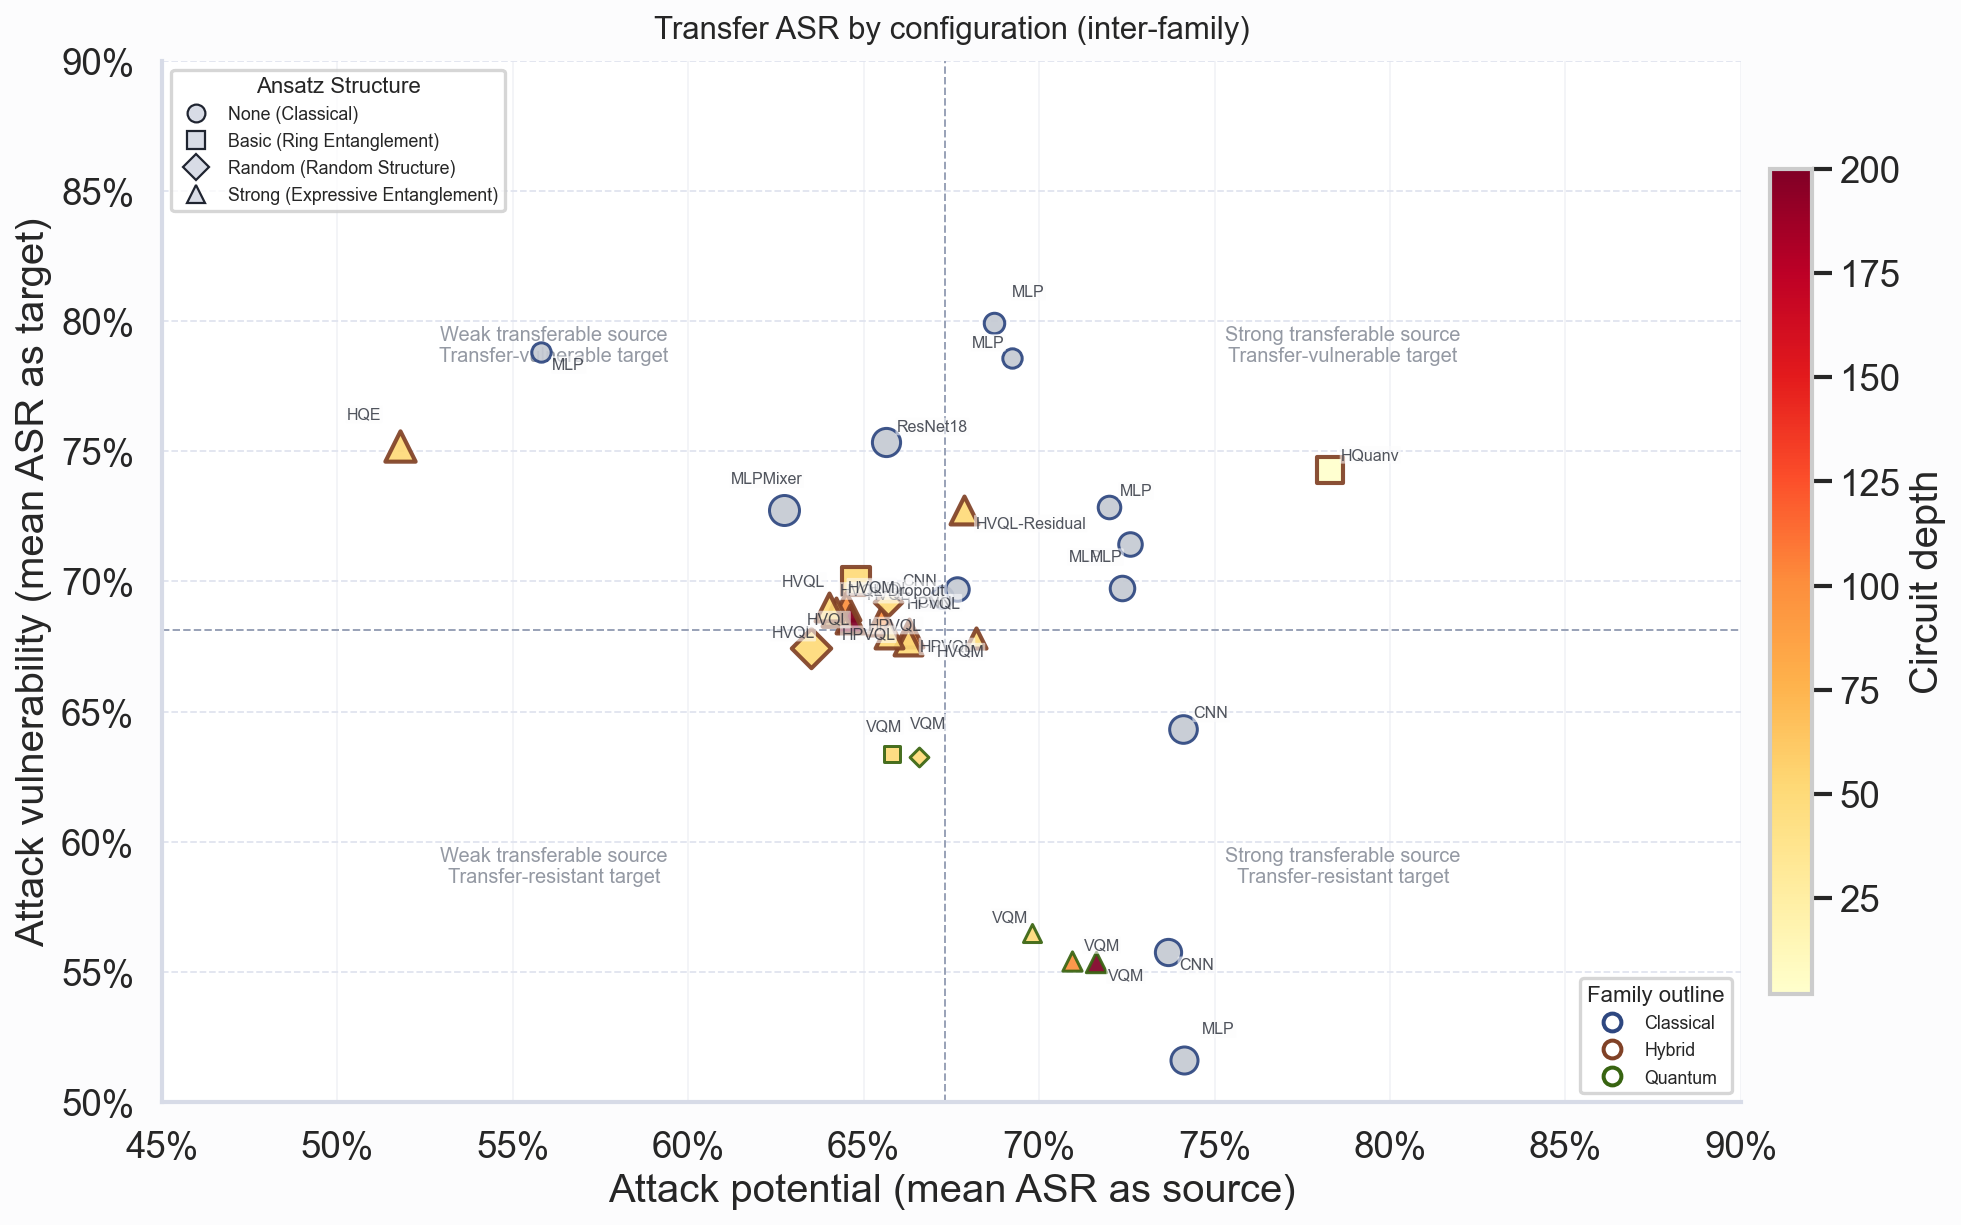

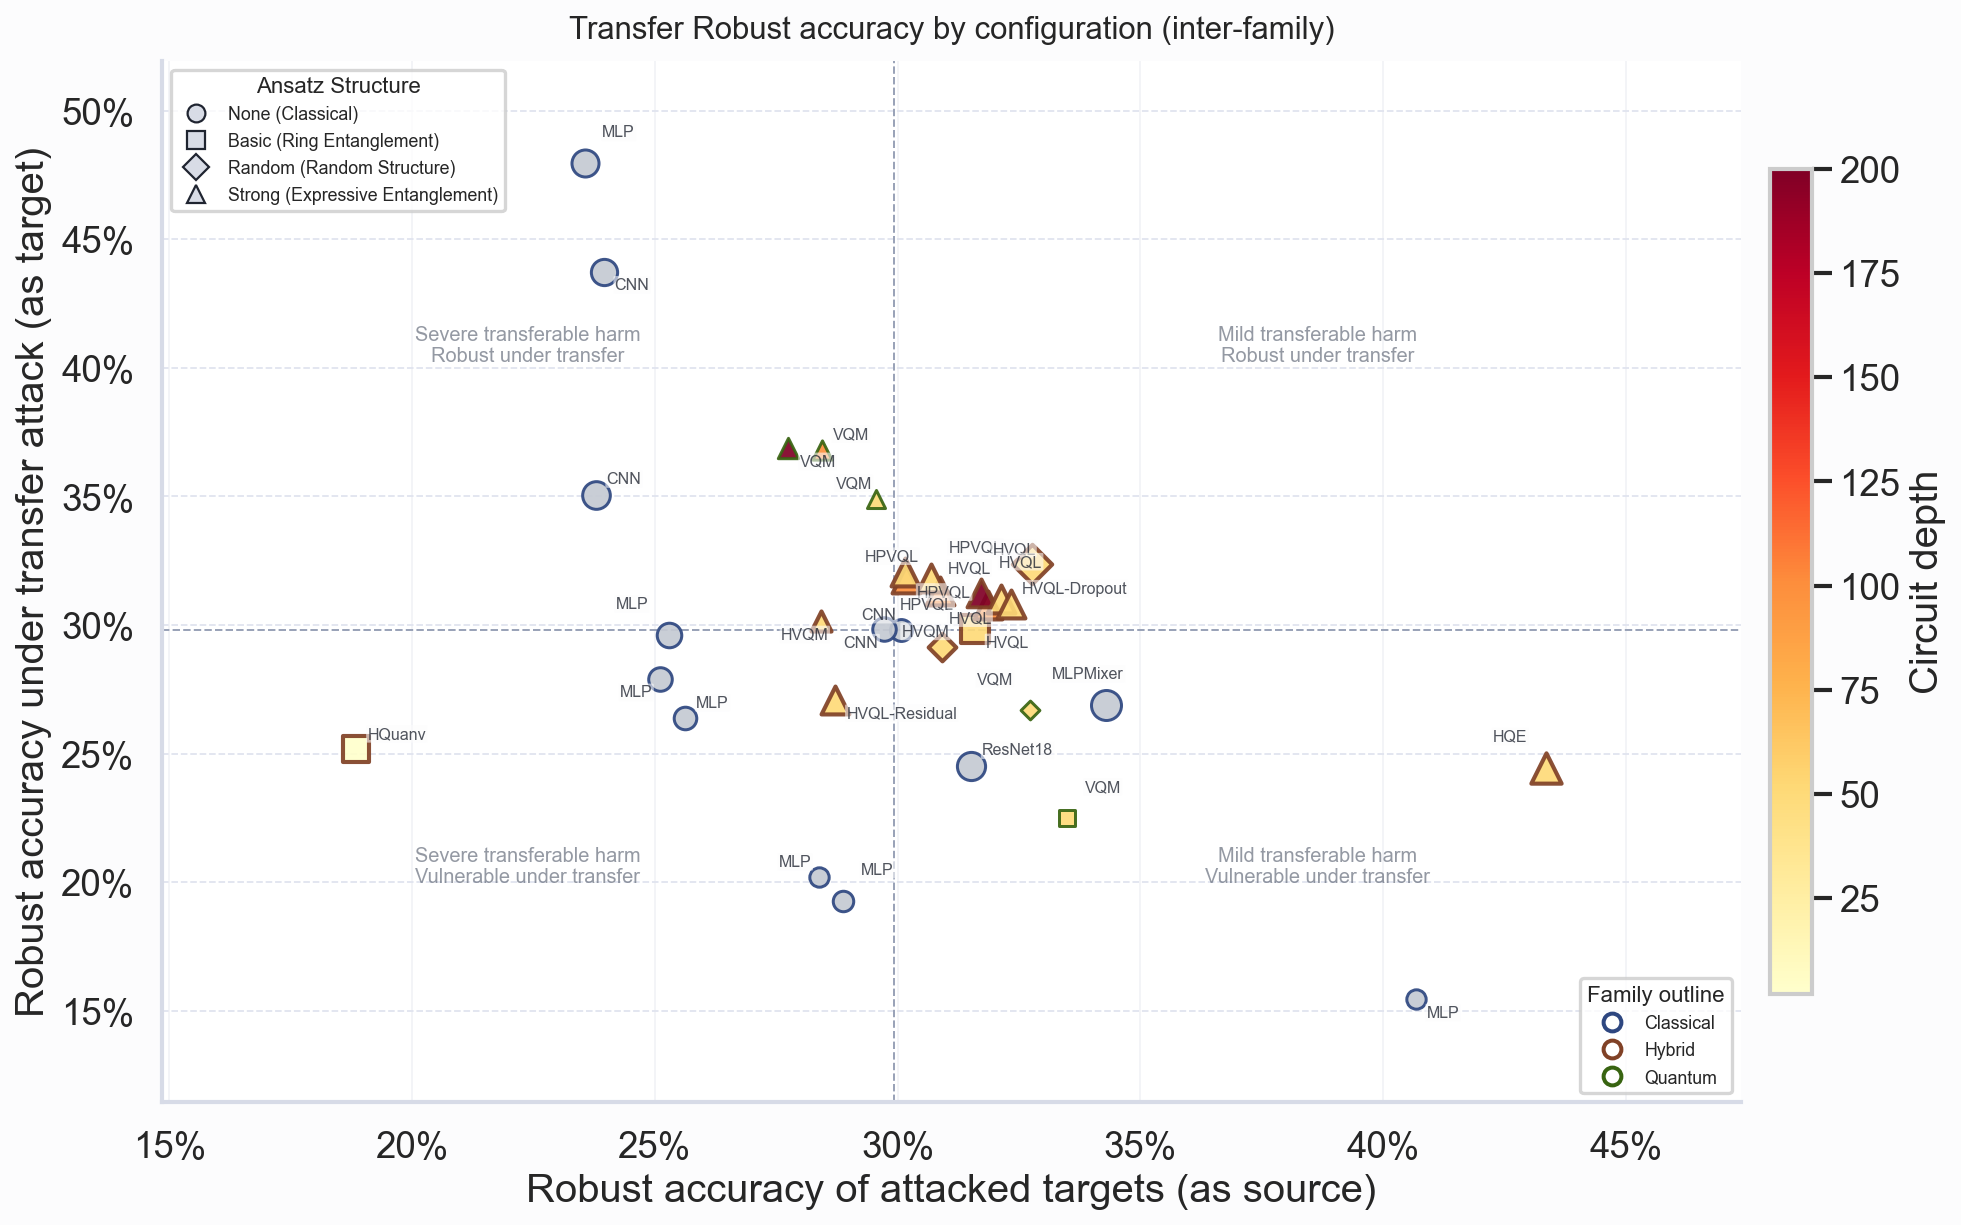

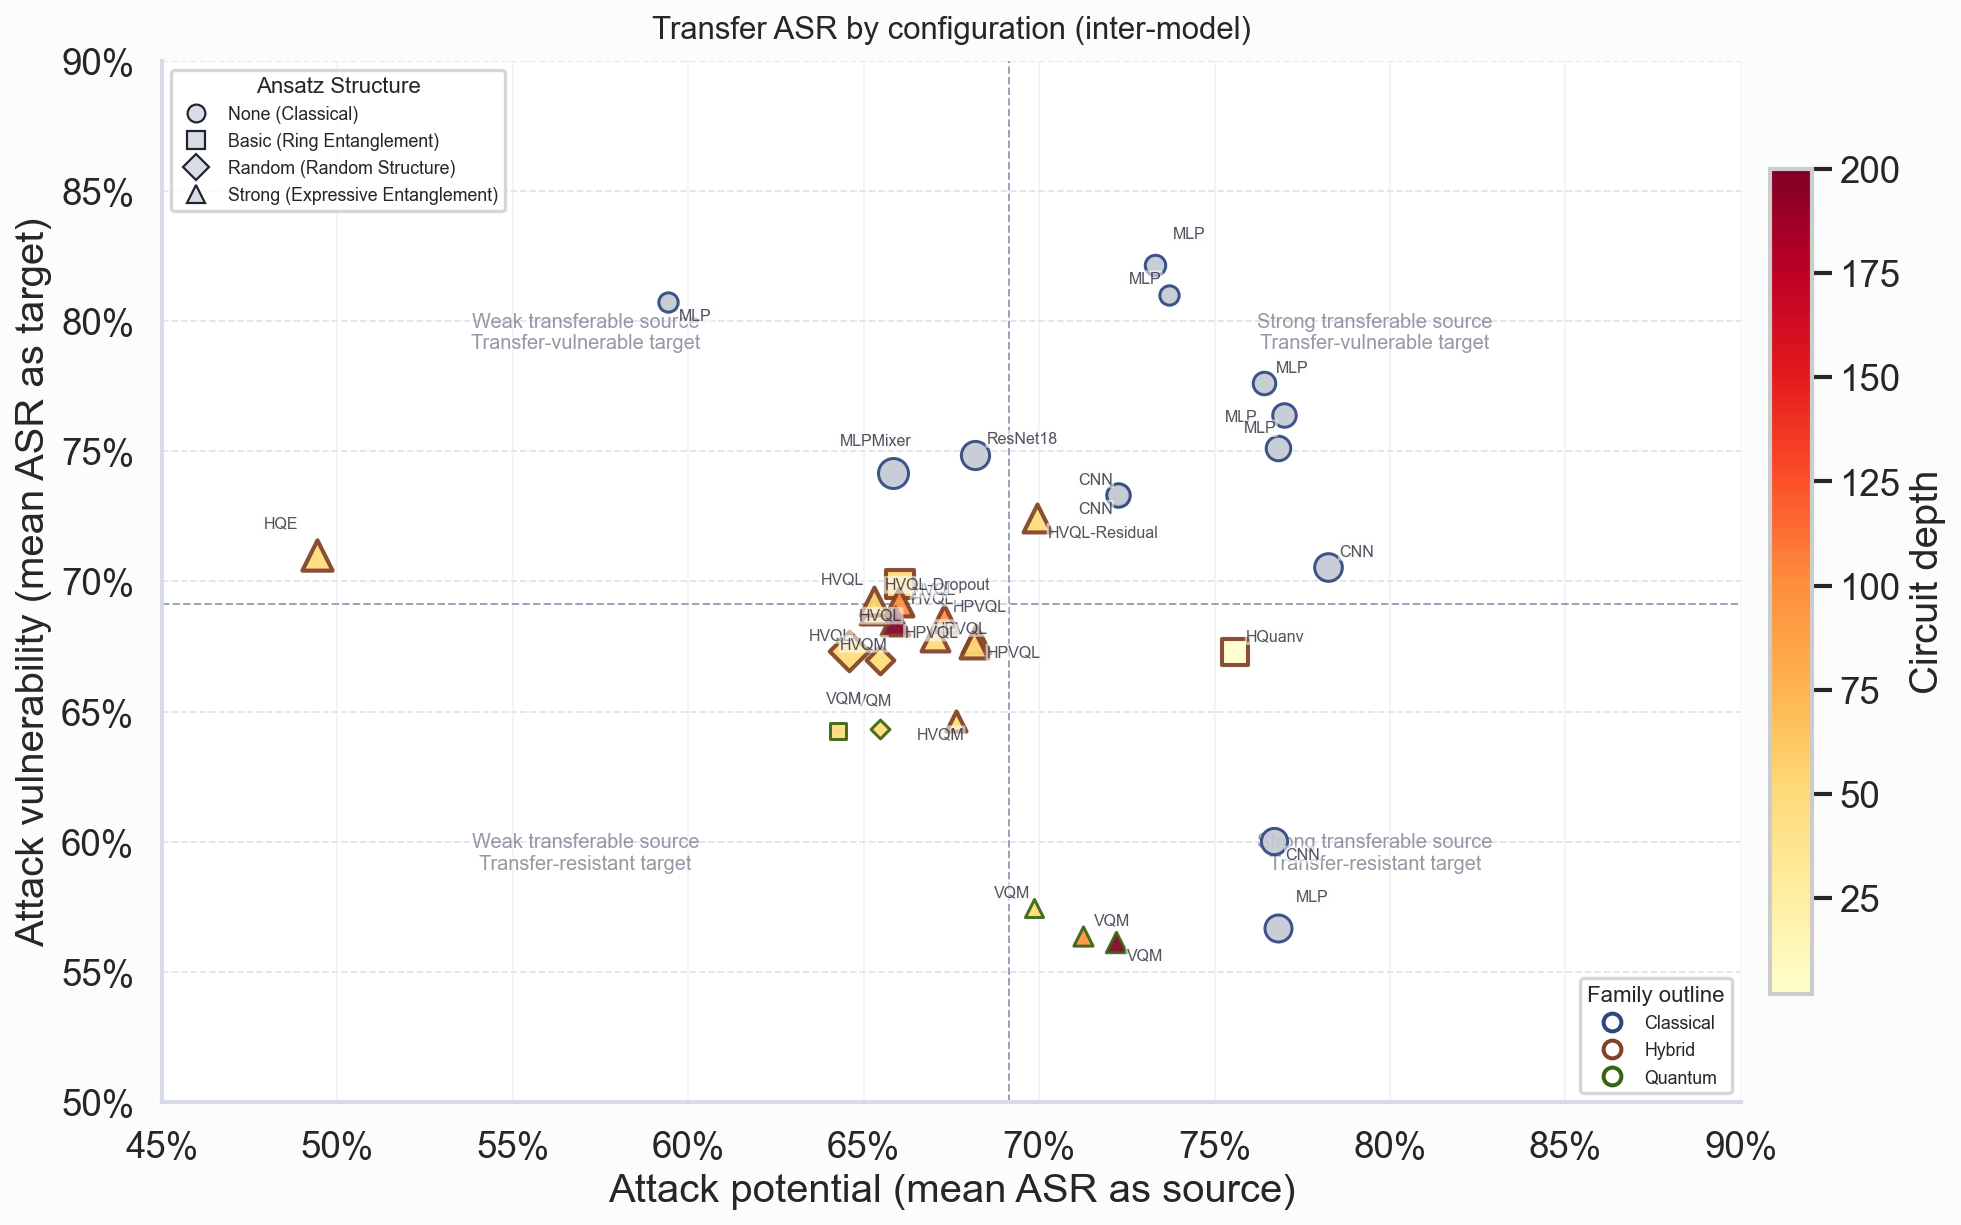

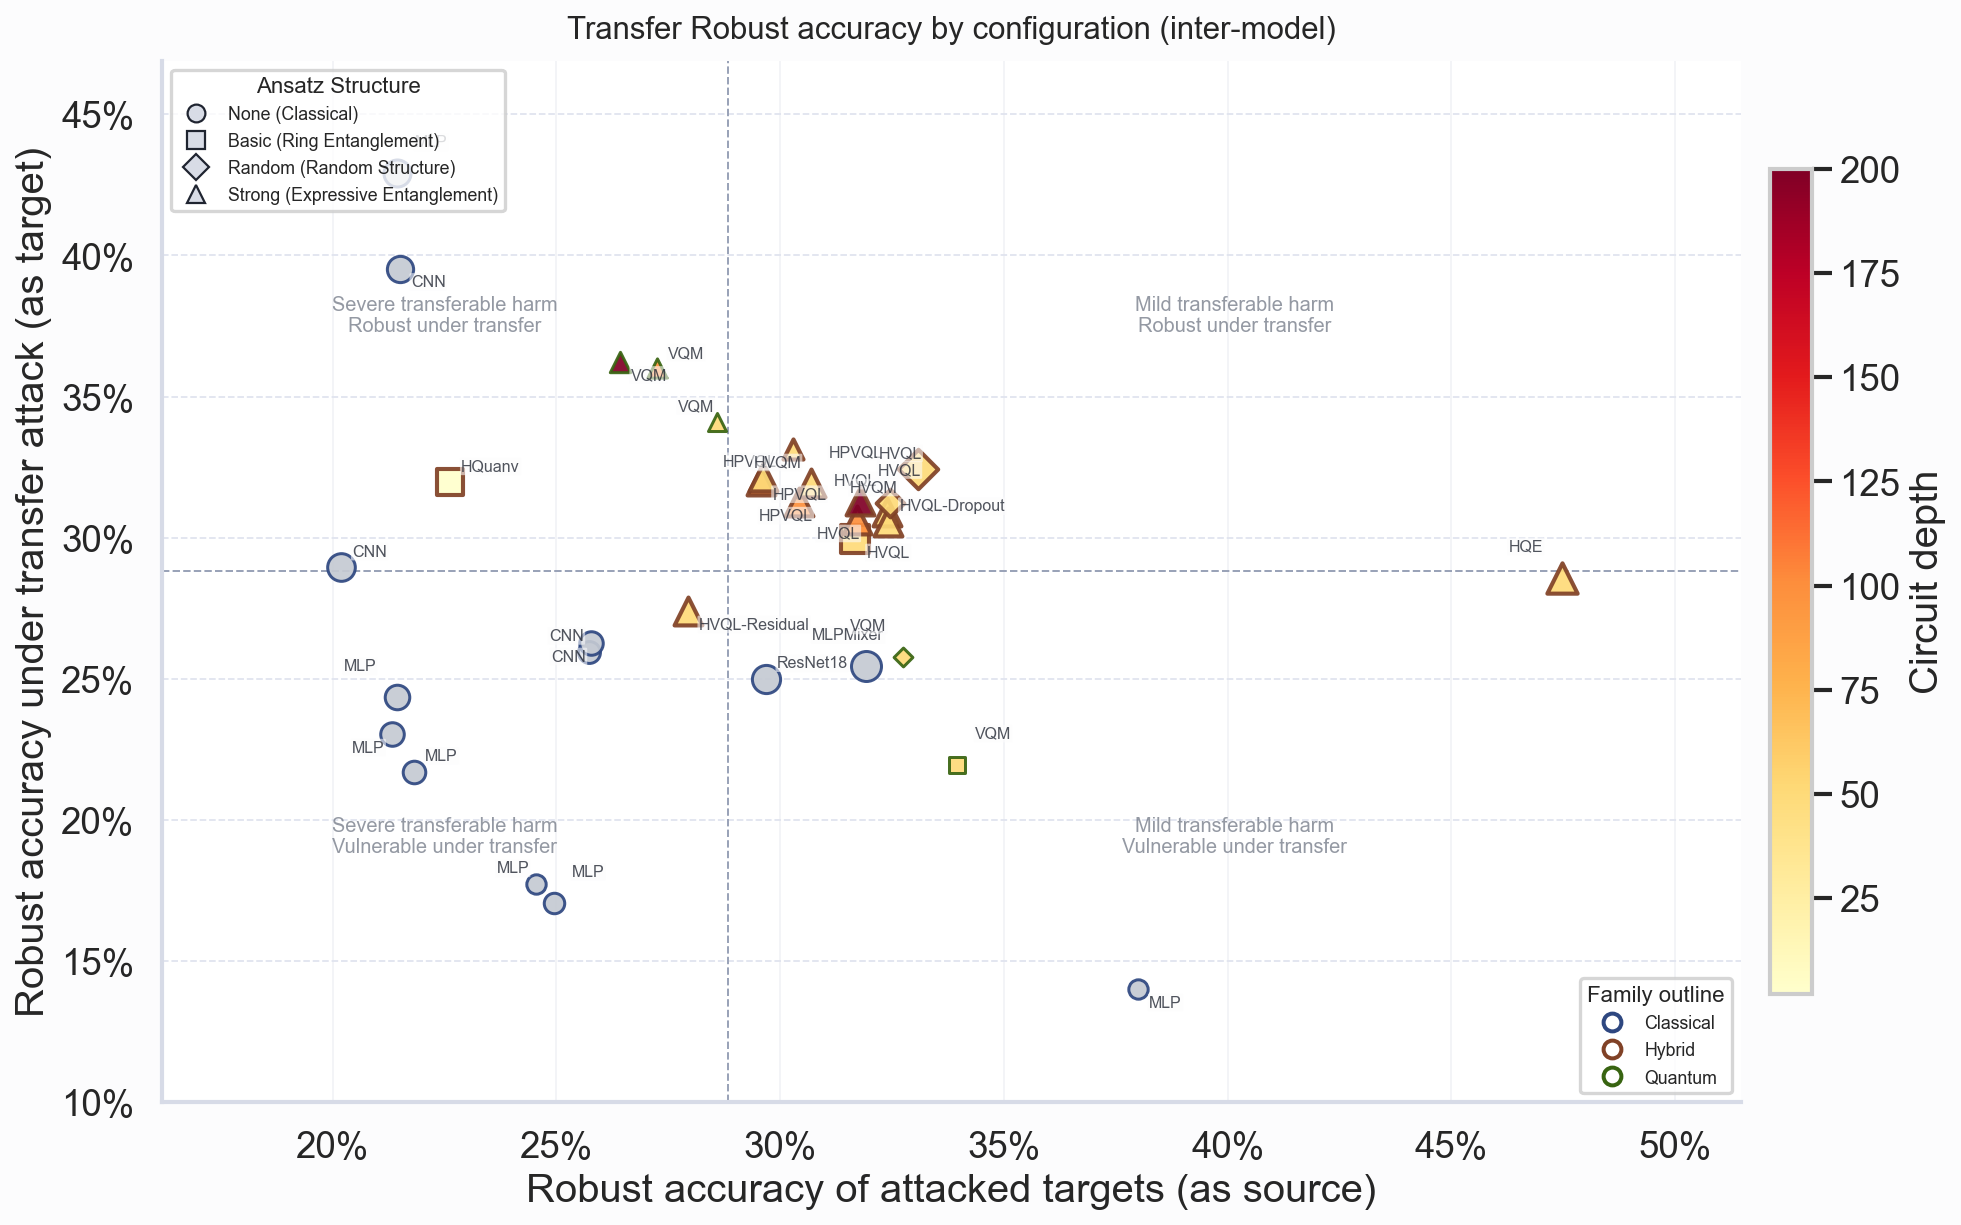

In [10]:
from IPython.display import Image, Markdown, display

for png in sorted(OUT.glob("*.png")):
    display(Image(filename=str(png)))